# EcoCiudad IA · Módulo 5 — Resumen de texto: Lead-n, TextRank y modelo abstractivo (DS5 XL-Sum, DS6 MLSUM)

**Objetivo.** Comparar tres métodos de resumen en español con ROUGE y declarar el mejor, sin vender de más.
**Datos.** `textos_residuos.csv` (Fase 2): muestras del *test* de XL-Sum (E1, BBC) y MLSUM (E2, El País), con su resumen de referencia. **Licencias no comerciales: el archivo no va al repositorio.**
**Dónde ejecutarlo.** En **Colab con GPU** (Entorno de ejecución → Cambiar tipo → GPU). En tu PC sin GPU el modelo abstractivo tardaría mucho.

**Decisiones fijadas antes de ver resultados**
1. **Métodos principales:** Lead-2 (baseline), TextRank-2 (implementación propia en `app/utils/texto.py`) y el modelo abstractivo. Las referencias son muy cortas (≈ una frase), por eso los extractivos se fijan en **2 oraciones** para la comparación principal. Lead-1, Lead-3, TextRank-1 y TextRank-3 se informan como **sensibilidad** y **no se usan para elegir**.
2. **Regla del ganador:** mayor **ROUGE-L (F1)** promediado entre E1 y E2 con el mismo peso; si la diferencia con el mejor es ≤ 0.005, gana el método más simple (Lead < TextRank < abstractivo).
3. **Incertidumbre:** diferencia de ROUGE-L frente a Lead-2 con **bootstrap pareado** (1000 remuestreos, semilla 42).
4. **Tokenizador de ROUGE propio** (minúsculas y secuencias de letras/dígitos Unicode, conserva tildes y ñ); se contrasta con el de `rouge-score` si está instalado.
5. **Filtro de residuos (D37):** el ROUGE principal usa **toda** la muestra de cada fuente. El subconjunto «residuos» solo se informa con el filtro estricto (≥ 3 apariciones de palabras clave) y si tiene al menos 30 artículos por fuente.
6. **Abstractivo:** el modelo del Hub se **verifica** en la celda 4 antes de usarlo. Si fue entrenado con XL-Sum, **favorece a E1**: se declara. Los parámetros de generación son los de la ficha del modelo `[VERIFICAR contra la ficha]`; el texto de entrada se trunca al límite de tokens.

**Qué pegarme al terminar:** `m5_resumen.txt` (se imprime en la última celda) y las tres líneas de verificación de las celdas 4 y 6.

In [1]:
# 1. Instalación (solo Colab; en tu PC instala a mano: pip install transformers sentencepiece rouge-score huggingface_hub)
import subprocess, sys
try:
    import google.colab  # noqa: F401
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "sentencepiece", "rouge-score", "huggingface_hub"], check=False)
except ImportError:
    print("No es Colab: se omite la instalación.")

In [3]:
# 2. Entorno y rutas (en el repositorio usa config.py; en Colab pide subir texto.py y textos_residuos.csv)
import json, re, time, datetime, platform, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

try:
    RAIZ = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "config.py").exists())
    sys.path.insert(0, str(RAIZ))
    import config
    from app.utils import texto as tx
    EN_COLAB, SEMILLA, SALIDA = False, config.RANDOM_STATE, RAIZ
    RUTA_TEXTOS = config.DATA_PROCESSED / config.ARCHIVOS_PROCESADOS["textos"]
except StopIteration:
    from google.colab import files
    faltan = [f for f in ["texto.py", "textos_residuos.csv"] if not Path(f).exists()]
    if faltan:
        print("Sube estos archivos:", faltan)
        files.upload()
    sys.path.insert(0, ".")
    import texto as tx
    EN_COLAB, SEMILLA, SALIDA = True, 42, Path("/content/salida_m5")
    RUTA_TEXTOS = Path("textos_residuos.csv")

def ruta(rel):
    p = SALIDA / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    return p

np.random.seed(SEMILLA)
print("Colab:", EN_COLAB, "| textos:", RUTA_TEXTOS, "| salida:", SALIDA)

Sube estos archivos: ['textos_residuos.csv']


Saving textos_residuos.csv to textos_residuos.csv
Colab: True | textos: textos_residuos.csv | salida: /content/salida_m5


In [6]:
# 3. Parámetros (todo lo editable está aquí)
LIMITE_DOCS = None             # None = muestras completas; un entero (p. ej. 20) = prueba rápida por fuente (no sobrescribe el meta final)
FUENTES = {"xlsum": "E1 XL-Sum (en dominio para el abstractivo)", "mlsum": "E2 MLSUM (fuera de dominio)"}
MODELO_ABSTRACTIVO = "csebuetnlp/mT5_multilingual_XLSum"   # [VERIFICAR] la celda 4 comprueba que existe y muestra su licencia
MAX_ENTRADA_TOKENS, MAX_SALIDA_TOKENS, NUM_BEAMS, NO_REPETIR_NGRAM, TAM_LOTE = 512, 84, 4, 2, 8   # [VERIFICAR contra la ficha del modelo]
N_PRINCIPAL, N_SENSIBILIDAD = 2, [1, 3]
EMPATE_ROUGE_L = 0.005
UMBRAL_APARICIONES, MIN_DOCS_SUBCONJUNTO = 3, 30
N_REMUESTREOS = 1000
REUSAR_SALIDAS = False         # True = reutiliza m5_salidas_abstractivo.csv si ya existe (por si se cayó la sesión)
HACER_DEMO_DS7 = False         # True = demostración jerárquica con DS7 (opcional, al final)
URL_DS7 = "https://documents1.worldbank.org/curated/en/697271544470229584/text/What-a-Waste-2-0-A-Global-Snapshot-of-Solid-Waste-Management-to-2050.txt"
MAX_PALABRAS_DS7 = 18000       # solo las primeras palabras, para no gastar la GPU gratuita
SUFIJO = "" if LIMITE_DOCS is None else "_prueba"
if LIMITE_DOCS is not None:
    print("⚠️ PRUEBA RÁPIDA: los resultados NO son los del informe y se guardan con sufijo", SUFIJO)

In [7]:
# 4. Verificación del modelo abstractivo en el Hub (necesita internet)
from huggingface_hub import HfApi
try:
    info = HfApi().model_info(MODELO_ABSTRACTIVO)
except Exception as e:
    raise RuntimeError(f"No se pudo verificar «{MODELO_ABSTRACTIVO}» ({type(e).__name__}). Comprueba el nombre en huggingface.co y tu internet; no sigas con un nombre sin verificar.") from e
ESTADO_MODELO = {"id": info.id, "sha": getattr(info, "sha", None), "ultima_modificacion": str(getattr(info, "last_modified", None)),
                 "licencia_ficha": getattr(getattr(info, "card_data", None), "license", None),
                 "etiquetas_licencia": [t for t in (info.tags or []) if str(t).startswith("license")]}
print("VERIFICACIÓN MODELO:", ESTADO_MODELO)

VERIFICACIÓN MODELO: {'id': 'csebuetnlp/mT5_multilingual_XLSum', 'sha': '2437a524effdbadc327ced84595508f1e32025b3', 'ultima_modificacion': '2022-08-13 13:15:36+00:00', 'licencia_ficha': None, 'etiquetas_licencia': []}


In [8]:
# 5. Datos: carga, comprobaciones y muestra de trabajo
COLS = ["id", "fuente", "particion", "texto", "resumen_ref", "es_residuos"]
df = pd.read_csv(RUTA_TEXTOS)
faltan = [c for c in COLS if c not in df.columns]
assert not faltan, f"Faltan columnas {faltan}. Columnas reales: {list(df.columns)}"
df = df.dropna(subset=["texto", "resumen_ref"])
df = df[(df["texto"].str.strip() != "") & (df["resumen_ref"].str.strip() != "")].copy()
df["id"] = df["id"].astype(str)
assert set(FUENTES) <= set(df["fuente"].unique()), f"Valores de fuente reales: {df['fuente'].unique()}"
df["n_aparic"] = df["texto"].map(tx.contar_palabras_residuos)
df["residuos_estricto"] = (df["n_aparic"] >= UMBRAL_APARICIONES).astype(int)
MUESTRA = {}
for f in FUENTES:
    sub = df[df["fuente"] == f]
    if LIMITE_DOCS is not None:
        sub = sub.sample(min(LIMITE_DOCS, len(sub)), random_state=SEMILLA)
    assert sub["id"].is_unique, f"{f}: hay id repetidos"
    MUESTRA[f] = sub.reset_index(drop=True)
    print(f"{f}: n = {len(sub)} | particiones = {sub['particion'].unique().tolist()} | es_residuos = {int(sub['es_residuos'].sum())} | "
          f"estricto (≥{UMBRAL_APARICIONES}) = {int(sub['residuos_estricto'].sum())} | palabras texto (media) = {sub['texto'].map(tx.contar_palabras).mean():.0f} | "
          f"palabras referencia (media) = {sub['resumen_ref'].map(tx.contar_palabras).mean():.1f}")

xlsum: n = 500 | particiones = ['test'] | es_residuos = 192 | estricto (≥3) = 39 | palabras texto (media) = 810 | palabras referencia (media) = 27.0
mlsum: n = 500 | particiones = ['test'] | es_residuos = 250 | estricto (≥3) = 53 | palabras texto (media) = 966 | palabras referencia (media) = 22.3


In [9]:
# 6. Verificación de ROUGE: tokenizador por defecto de rouge-score frente al propio, y coincidencia de ambas implementaciones
try:
    from rouge_score import rouge_scorer
    class TokPropio:
        def tokenize(self, texto):
            return tx.tokenizar(texto)
    sc_def = rouge_scorer.RougeScorer(["rouge1", "rougeL"])
    sc_prop = rouge_scorer.RougeScorer(["rouge1", "rougeL"], tokenizer=TokPropio())
    for ref, hip in [("pequeña", "pequeño"), ("la canción de la montaña", "la canción de la montaña")]:
        d, p = sc_def.score(ref, hip)["rouge1"].fmeasure, sc_prop.score(ref, hip)["rouge1"].fmeasure
        print(f"VERIFICACIÓN TOKENIZADOR: ref={ref!r} hip={hip!r} -> rouge1 por defecto = {d:.3f}, tokenizador propio = {p:.3f}")
    pares = MUESTRA["xlsum"].head(50)
    dif = {"rouge1": 0.0, "rougeL": 0.0}
    for ref, txt in zip(pares["resumen_ref"], pares["texto"]):
        hip = tx.lead_n(txt, N_PRINCIPAL)
        mio, ext = tx.rouge_f1(ref, hip), sc_prop.score(ref, hip)
        for k in dif:
            dif[k] = max(dif[k], abs(mio[k] - ext[k].fmeasure))
    print("VERIFICACIÓN IMPLEMENTACIÓN: diferencia máxima entre ROUGE propio y rouge-score (mismo tokenizador) en 50 pares:", {k: round(v, 6) for k, v in dif.items()})
except Exception as e:  # no bloquea: solo informa
    print("Verificación con rouge-score omitida:", type(e).__name__, str(e)[:200])

VERIFICACIÓN TOKENIZADOR: ref='pequeña' hip='pequeño' -> rouge1 por defecto = 0.500, tokenizador propio = 0.000
VERIFICACIÓN TOKENIZADOR: ref='la canción de la montaña' hip='la canción de la montaña' -> rouge1 por defecto = 1.000, tokenizador propio = 1.000
VERIFICACIÓN IMPLEMENTACIÓN: diferencia máxima entre ROUGE propio y rouge-score (mismo tokenizador) en 50 pares: {'rouge1': 0.0, 'rougeL': 0.0}


In [10]:
# 7. Métodos extractivos: Lead-n y TextRank-n (n = 1, 2, 3), con tiempo por documento
NS = sorted(set([N_PRINCIPAL] + N_SENSIBILIDAD))
HIP, SEG = {f: {} for f in FUENTES}, {f: {} for f in FUENTES}
for f in FUENTES:
    textos = MUESTRA[f]["texto"].tolist()
    for n in NS:
        for nombre, fn in [(f"Lead-{n}", tx.lead_n), (f"TextRank-{n}", tx.textrank)]:
            t0 = time.perf_counter()
            HIP[f][nombre] = [fn(t, n) for t in textos]
            SEG[f][nombre] = (time.perf_counter() - t0) / max(len(textos), 1)
print("Extractivos listos:", {m: round(s, 4) for m, s in SEG["xlsum"].items()}, "(s/doc en E1)")

Extractivos listos: {'Lead-1': 0.0023, 'TextRank-1': 0.0031, 'Lead-2': 0.0012, 'TextRank-2': 0.0031, 'Lead-3': 0.0012, 'TextRank-3': 0.003} (s/doc en E1)


In [11]:
# 8. Modelo abstractivo: carga y generación por lotes (float32; lotes ordenados por longitud; si falta memoria, baja el lote)
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
NOMBRE_GPU = torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "sin GPU"
print("Dispositivo:", DISPOSITIVO, NOMBRE_GPU)
if DISPOSITIVO == "cpu":
    print("⚠️ Sin GPU esto puede tardar mucho. Usa LIMITE_DOCS = 20 para una prueba.")
REV = ESTADO_MODELO.get("sha")
tok = AutoTokenizer.from_pretrained(MODELO_ABSTRACTIVO, revision=REV)
modelo = AutoModelForSeq2SeqLM.from_pretrained(MODELO_ABSTRACTIVO, revision=REV).to(DISPOSITIVO).eval()

def resumir_abstractivo(textos, lote=TAM_LOTE):
    salidas = [None] * len(textos)
    orden = sorted(range(len(textos)), key=lambda i: len(textos[i]))
    i = 0
    while i < len(orden):
        idx = orden[i:i + lote]
        try:
            lote_tok = tok([tx.normalizar_espacios(textos[j]) for j in idx], return_tensors="pt", truncation=True,
                           max_length=MAX_ENTRADA_TOKENS, padding=True).to(DISPOSITIVO)
            with torch.no_grad():
                ids = modelo.generate(**lote_tok, max_new_tokens=MAX_SALIDA_TOKENS, num_beams=NUM_BEAMS, no_repeat_ngram_size=NO_REPETIR_NGRAM)
            for j, s in zip(idx, tok.batch_decode(ids, skip_special_tokens=True)):
                salidas[j] = s.strip()
            i += len(idx)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if lote == 1:
                raise
            lote = max(1, lote // 2)
            print("Memoria insuficiente: lote =", lote)
    return salidas

ARCH_SALIDAS = ruta(f"data/processed/m5_salidas_abstractivo{SUFIJO}.csv")
previo = pd.read_csv(ARCH_SALIDAS, dtype={"id": str}) if (REUSAR_SALIDAS and ARCH_SALIDAS.exists()) else None
filas_salida = []
for f in FUENTES:
    sub = MUESTRA[f]
    if previo is not None and set(sub["id"]) <= set(previo.loc[previo["fuente"] == f, "id"]):
        m = previo[previo["fuente"] == f].set_index("id")
        HIP[f]["Abstractivo"] = [m.loc[i, "resumen_abstractivo"] for i in sub["id"]]
        SEG[f]["Abstractivo"] = float(m["segundos_por_doc"].iloc[0])
        print(f"{f}: reutilizado de {ARCH_SALIDAS.name}")
    else:
        t0 = time.perf_counter()
        HIP[f]["Abstractivo"] = resumir_abstractivo(sub["texto"].tolist())
        SEG[f]["Abstractivo"] = (time.perf_counter() - t0) / max(len(sub), 1)
        print(f"{f}: {len(sub)} resúmenes en {time.perf_counter() - t0:.0f} s")
    filas_salida += [{"id": i, "fuente": f, "resumen_abstractivo": h, "segundos_por_doc": SEG[f]["Abstractivo"]} for i, h in zip(sub["id"], HIP[f]["Abstractivo"])]
pd.DataFrame(filas_salida).to_csv(ARCH_SALIDAS, index=False)

Dispositivo: cuda Tesla T4


config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

... (6 outputs left out)

[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

xlsum: 500 resúmenes en 200 s


[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=84) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

mlsum: 500 resúmenes en 209 s


In [12]:
# 9. Puntuación de todos los métodos (ROUGE-1/2/L en F1, palabras y ratio de compresión por documento)
filas = []
for f in FUENTES:
    sub = MUESTRA[f]
    for metodo, hips in HIP[f].items():
        for i, ref, txt, hip in zip(sub["id"], sub["resumen_ref"], sub["texto"], hips):
            filas.append({"id": i, "fuente": f, "metodo": metodo, **tx.rouge_f1(ref, hip), "palabras_hip": tx.contar_palabras(hip),
                          "ratio": tx.ratio_compresion(hip, txt)})
DOC = pd.DataFrame(filas).merge(df[["id", "fuente", "es_residuos", "residuos_estricto"]], on=["id", "fuente"], how="left")
TABLA = (DOC.groupby(["fuente", "metodo"]).agg(n=("id", "size"), rouge1=("rouge1", "mean"), rouge2=("rouge2", "mean"), rougeL=("rougeL", "mean"),
         rougeL_desv=("rougeL", "std"), palabras_hip=("palabras_hip", "mean"), ratio=("ratio", "mean")).reset_index())
TABLA["seg_por_doc"] = [SEG[f][m] for f, m in zip(TABLA["fuente"], TABLA["metodo"])]
print(TABLA.round(4).to_string(index=False))

fuente      metodo   n  rouge1  rouge2  rougeL  rougeL_desv  palabras_hip  ratio  seg_por_doc
 mlsum Abstractivo 500  0.1999  0.0440  0.1582       0.1003        18.426 0.0304       0.4189
 mlsum      Lead-1 500  0.1907  0.0470  0.1492       0.1037        24.126 0.0390       0.0015
 mlsum      Lead-2 500  0.2049  0.0530  0.1504       0.0907        51.420 0.0842       0.0035
 mlsum      Lead-3 500  0.1978  0.0569  0.1435       0.0771        77.270 0.1239       0.0015
 mlsum  TextRank-1 500  0.2140  0.0511  0.1556       0.1029        44.276 0.0623       0.0038
 mlsum  TextRank-2 500  0.1904  0.0502  0.1383       0.0751        83.646 0.1193       0.0065
 mlsum  TextRank-3 500  0.1642  0.0467  0.1201       0.0606       120.098 0.1729       0.0039
 xlsum Abstractivo 500  0.2902  0.1064  0.2232       0.1448        16.694 0.0321       0.3998
 xlsum      Lead-1 500  0.1905  0.0457  0.1494       0.0961        17.298 0.0328       0.0023
 xlsum      Lead-2 500  0.2144  0.0402  0.1484       0.0690 

In [13]:
# 10. Ganador (regla fijada), bootstrap pareado frente a Lead-N y subconjuntos
PRINCIPALES = [f"Lead-{N_PRINCIPAL}", f"TextRank-{N_PRINCIPAL}", "Abstractivo"]      # de más simple a más complejo
punt = {m: float(np.mean([TABLA[(TABLA.fuente == f) & (TABLA.metodo == m)]["rougeL"].iloc[0] for f in FUENTES])) for m in PRINCIPALES}
mejor = max(punt.values())
GANADOR = next(m for m in PRINCIPALES if mejor - punt[m] <= EMPATE_ROUGE_L)
print("ROUGE-L medio (E1 y E2):", {m: round(v, 4) for m, v in punt.items()}, "-> GANADOR:", GANADOR)

rng = np.random.default_rng(SEMILLA)
BOOT = {}
for f in FUENTES:
    p = DOC[DOC.fuente == f].pivot(index="id", columns="metodo", values="rougeL")
    for m in PRINCIPALES[1:]:
        d = (p[m] - p[PRINCIPALES[0]]).to_numpy()
        medias = d[rng.integers(0, len(d), (N_REMUESTREOS, len(d)))].mean(axis=1)
        lo, hi = np.percentile(medias, [2.5, 97.5])
        BOOT[f"{f}|{m}"] = {"dif_media": float(d.mean()), "ic95": [float(lo), float(hi)], "excluye_cero": bool(lo > 0 or hi < 0), "n": int(len(d))}
        print(f"{f}: {m} − {PRINCIPALES[0]}  ΔROUGE-L = {d.mean():+.4f}  IC95 [{lo:+.4f}, {hi:+.4f}]  {'(excluye 0)' if BOOT[f'{f}|{m}']['excluye_cero'] else '(incluye 0)'}")

SUBC = {}
for nombre, col in [("residuos_palabra", "es_residuos"), ("residuos_estricto", "residuos_estricto")]:
    for f in FUENTES:
        s = DOC[(DOC.fuente == f) & (DOC[col] == 1) & (DOC.metodo.isin(PRINCIPALES))]
        n = int(s[s.metodo == PRINCIPALES[0]].shape[0])
        if nombre == "residuos_estricto" and n < MIN_DOCS_SUBCONJUNTO:
            SUBC[f"{nombre}|{f}"] = {"n": n, "nota": f"omitido: menos de {MIN_DOCS_SUBCONJUNTO} artículos"}
        else:
            SUBC[f"{nombre}|{f}"] = {"n": n, **{m: float(s[s.metodo == m]["rougeL"].mean()) for m in PRINCIPALES}}
print("Subconjuntos (ROUGE-L):", json.dumps(SUBC, ensure_ascii=False))

ROUGE-L medio (E1 y E2): {'Lead-2': 0.1494, 'TextRank-2': 0.1395, 'Abstractivo': 0.1907} -> GANADOR: Abstractivo
xlsum: TextRank-2 − Lead-2  ΔROUGE-L = -0.0076  IC95 [-0.0132, -0.0018]  (excluye 0)
xlsum: Abstractivo − Lead-2  ΔROUGE-L = +0.0748  IC95 [+0.0627, +0.0873]  (excluye 0)
mlsum: TextRank-2 − Lead-2  ΔROUGE-L = -0.0121  IC95 [-0.0216, -0.0034]  (excluye 0)
mlsum: Abstractivo − Lead-2  ΔROUGE-L = +0.0077  IC95 [-0.0019, +0.0176]  (incluye 0)
Subconjuntos (ROUGE-L): {"residuos_palabra|xlsum": {"n": 192, "Lead-2": 0.14297652437743757, "TextRank-2": 0.13321885133508937, "Abstractivo": 0.1977948550214664}, "residuos_palabra|mlsum": {"n": 250, "Lead-2": 0.1433845817102353, "TextRank-2": 0.13670516936860685, "Abstractivo": 0.1570043268518172}, "residuos_estricto|xlsum": {"n": 39, "Lead-2": 0.12989567924244005, "TextRank-2": 0.13064789420218675, "Abstractivo": 0.18775952601506743}, "residuos_estricto|mlsum": {"n": 53, "Lead-2": 0.15238128935621775, "TextRank-2": 0.1297033051516424, "

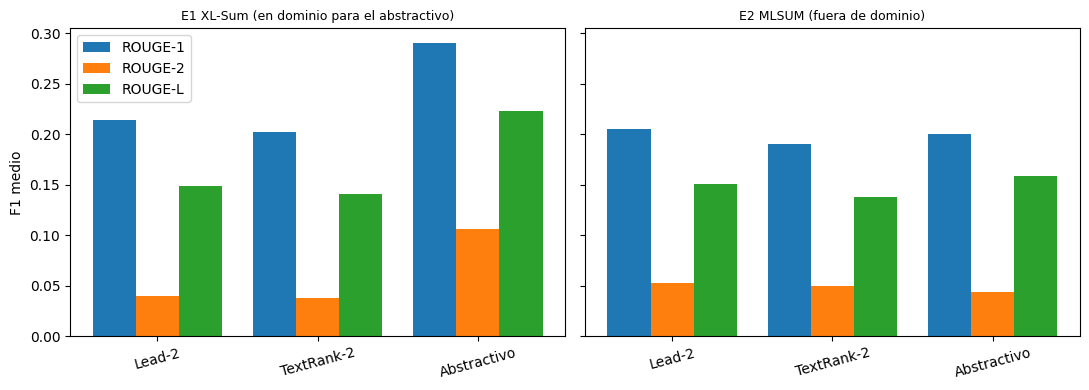


[xlsum · 140908_ultnot_asteroide_tierra_wbm] ARTÍCULO: El meteorito cayó en un área boscosa cerca del aeropuerto y una base aérea en Managua. El meteorito cayó cerca del aeropuerto internacional en Managua, la capital de Nicaragua, el pasado sábado por la…
  REFERENCIA: Científicos en Nicaragua pidieron asistencia internacional para analizar la posible relación de un meteorito que impactó su territorio al tiempo que un asteroide pasara por la Tierra.
  Lead-2: El meteorito cayó en un área boscosa cerca del aeropuerto y una base aérea en Managua. El meteorito cayó cerca del aeropuerto internacional en Managua, la capital de Nicaragua, el pasado sábado por la noche, según informaron las autoridades.
  TextRank-2: El meteorito cayó en un área boscosa cerca del aeropuerto y una base aérea en Managua. El meteorito cayó cerca del aeropuerto internacional en Managua, la capital de Nicaragua, el pasado sábado por la noche, según informaron las autoridades.
  Abstractivo: Un cráter de roca esp

In [14]:
# 11. Figura y ejemplos cualitativos (para la revisión humana de fidelidad y fluidez)
fig, ejes = plt.subplots(1, len(FUENTES), figsize=(11, 4), sharey=True)
for ax, f in zip(np.atleast_1d(ejes), FUENTES):
    t = TABLA[(TABLA.fuente == f) & (TABLA.metodo.isin(PRINCIPALES))].set_index("metodo").loc[PRINCIPALES]
    x = np.arange(len(PRINCIPALES))
    for k, (col, et) in enumerate([("rouge1", "ROUGE-1"), ("rouge2", "ROUGE-2"), ("rougeL", "ROUGE-L")]):
        ax.bar(x + (k - 1) * 0.27, t[col], 0.27, label=et)
    ax.set_xticks(x); ax.set_xticklabels(PRINCIPALES, rotation=15); ax.set_title(FUENTES[f], fontsize=9)
np.atleast_1d(ejes)[0].set_ylabel("F1 medio"); np.atleast_1d(ejes)[0].legend()
plt.tight_layout(); plt.savefig(ruta("docs/figuras/m5_comparacion.png"), dpi=130); plt.show()

EJ = []
for f in FUENTES:
    sub = MUESTRA[f]
    for pos in sub.sample(min(3, len(sub)), random_state=SEMILLA).index:
        fila = {"id": sub.loc[pos, "id"], "fuente": f, "texto_inicio": sub.loc[pos, "texto"][:400], "referencia": sub.loc[pos, "resumen_ref"]}
        fila.update({m: HIP[f][m][pos] for m in PRINCIPALES})
        EJ.append(fila)
        print(f"\n[{f} · {fila['id']}] ARTÍCULO: {fila['texto_inicio'][:200]}…\n  REFERENCIA: {fila['referencia']}")
        for m in PRINCIPALES:
            print(f"  {m}: {fila[m][:300]}")
pd.DataFrame(EJ).to_csv(ruta(f"data/processed/m5_ejemplos{SUFIJO}.csv"), index=False)

In [15]:
# 12. Guardar resultados, meta y resumen de texto (y, en Colab, empaquetar para descargar)
from importlib.metadata import version, PackageNotFoundError
def v(n):
    try:
        return version(n)
    except PackageNotFoundError:
        return None
G = TABLA[TABLA.metodo == GANADOR].set_index("fuente")
met = {k: float(G[k].mean()) for k in ["rouge1", "rouge2", "rougeL", "ratio"]}
meta = {
    "modulo": "resumen", "modelo": GANADOR, "fecha": datetime.date.today().isoformat(),
    "dataset": "E1 XL-Sum (es, test) y E2 MLSUM (es, test): muestras de textos_residuos.csv (D32, D36); referencias de la BBC y de El País",
    "n_entrenamiento": 0, "n_prueba": int(sum(len(MUESTRA[f]) for f in FUENTES)), "n_por_fuente": {f: int(len(MUESTRA[f])) for f in FUENTES},
    "parametros": {"n_principal": N_PRINCIPAL, "n_sensibilidad": N_SENSIBILIDAD, "empate_rouge_l": EMPATE_ROUGE_L, "remuestreos": N_REMUESTREOS, "semilla": SEMILLA,
                   "limite_docs": LIMITE_DOCS, "umbral_apariciones": UMBRAL_APARICIONES},
    "metricas": {"rouge1": met["rouge1"], "rouge2": met["rouge2"], "rougeL": met["rougeL"], "ratio_compresion": met["ratio"]},
    "metricas_por_fuente": {f: {k: float(G.loc[f, k]) for k in ["rouge1", "rouge2", "rougeL", "ratio"]} for f in FUENTES},
    "features": [], "clases": [],
    "librerias": {"numpy": np.__version__, "pandas": pd.__version__, "torch": v("torch"), "transformers": v("transformers"),
                  "sentencepiece": v("sentencepiece"), "rouge-score": v("rouge-score"), "huggingface_hub": v("huggingface_hub")},
    "ganador_evaluacion": GANADOR, "metodos_principales": PRINCIPALES, "rouge_l_medio": punt,
    "regla_seleccion": f"mayor ROUGE-L (F1) medio entre E1 y E2; empate (≤ {EMPATE_ROUGE_L}) -> método más simple",
    "tokenizador_rouge": "propio: minúsculas y secuencias de letras/dígitos Unicode (app/utils/texto.py::tokenizar)",
    "evaluacion": json.loads(TABLA.round(6).to_json(orient="records")), "bootstrap_vs_lead": BOOT, "subconjuntos_residuos": SUBC,
    "abstractivo": {"modelo_hub": ESTADO_MODELO, "max_entrada_tokens": MAX_ENTRADA_TOKENS, "max_salida_tokens": MAX_SALIDA_TOKENS, "num_beams": NUM_BEAMS,
                    "no_repetir_ngram": NO_REPETIR_NGRAM, "dispositivo": DISPOSITIVO, "gpu": NOMBRE_GPU, "precision": "float32",
                    "nota_dominio": "Si el modelo fue entrenado con XL-Sum, E1 lo favorece; E2 es la comparación más justa."},
    "notas": "Referencias de una frase: los ROUGE absolutos son bajos para todos los métodos; compáralos entre sí, no con otros trabajos. Evaluación en noticias, no en normas. El abstractivo puede inventar datos.",
}
ruta(f"models/resumen_meta{SUFIJO}.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
TABLA.round(6).to_csv(ruta(f"data/processed/m5_resultados{SUFIJO}.csv"), index=False)
DOC.round(6).to_csv(ruta(f"data/processed/m5_por_documento{SUFIJO}.csv"), index=False)

lineas = [f"M5 RESUMEN{' (PRUEBA RÁPIDA)' if SUFIJO else ''} · {meta['fecha']} · dispositivo {DISPOSITIVO} {NOMBRE_GPU} · semilla {SEMILLA}",
          f"Modelo abstractivo: {json.dumps(ESTADO_MODELO, ensure_ascii=False)}",
          f"n por fuente: {meta['n_por_fuente']} | librerías: {meta['librerias']}", "", TABLA.round(4).to_string(index=False), "",
          f"ROUGE-L medio (E1 y E2): { {m: round(x, 4) for m, x in punt.items()} } -> GANADOR: {GANADOR}"]
lineas += [f"{k}: Δ={b['dif_media']:+.4f} IC95 [{b['ic95'][0]:+.4f}, {b['ic95'][1]:+.4f}] {'excluye 0' if b['excluye_cero'] else 'incluye 0'}" for k, b in BOOT.items()]
lineas += ["Subconjuntos: " + json.dumps(SUBC, ensure_ascii=False)]
ruta(f"data/processed/m5_resumen{SUFIJO}.txt").write_text("\n".join(lineas), encoding="utf-8")
print("\n".join(lineas))

if EN_COLAB:
    zip_path = Path(f"/content/salida_fase7A{SUFIJO}.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in SALIDA.rglob("*"):
            if p.is_file():
                z.write(p, p.relative_to(SALIDA))
    files.download(str(zip_path))

M5 RESUMEN · 2026-11-24 · dispositivo cuda Tesla T4 · semilla 42
Modelo abstractivo: {"id": "csebuetnlp/mT5_multilingual_XLSum", "sha": "2437a524effdbadc327ced84595508f1e32025b3", "ultima_modificacion": "2022-08-13 13:15:36+00:00", "licencia_ficha": null, "etiquetas_licencia": []}
n por fuente: {'xlsum': 500, 'mlsum': 500} | librerías: {'numpy': '2.4.6', 'pandas': '2.2.3', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'sentencepiece': '0.2.2', 'rouge-score': '0.1.2', 'huggingface_hub': '1.33.0'}

fuente      metodo   n  rouge1  rouge2  rougeL  rougeL_desv  palabras_hip  ratio  seg_por_doc
 mlsum Abstractivo 500  0.1999  0.0440  0.1582       0.1003        18.426 0.0304       0.4189
 mlsum      Lead-1 500  0.1907  0.0470  0.1492       0.1037        24.126 0.0390       0.0015
 mlsum      Lead-2 500  0.2049  0.0530  0.1504       0.0907        51.420 0.0842       0.0035
 mlsum      Lead-3 500  0.1978  0.0569  0.1435       0.0771        77.270 0.1239       0.0015
 mlsum  TextRank-1 500 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# 13. (Opcional) Demostración jerárquica con un documento largo de DS7, sin ROUGE: se revisa a mano (fidelidad, cobertura, fluidez)
if HACER_DEMO_DS7:
    import urllib.request
    crudo = urllib.request.urlopen(URL_DS7, timeout=90).read().decode("utf-8", errors="replace")
    texto_demo = " ".join(crudo.split()[:MAX_PALABRAS_DS7])
    ext, ext_niv = tx.resumen_jerarquico(texto_demo, lambda b: tx.textrank(b, 2), palabras=450)
    abst, abst_niv = tx.resumen_jerarquico(texto_demo, lambda b: resumir_abstractivo([b])[0], palabras=450)
    demo = {"fuente": URL_DS7, "licencia": "[VERIFICAR]", "palabras_usadas": len(texto_demo.split()), "bloques_nivel1": len(tx.dividir_en_bloques(texto_demo, 450)),
            "resumen_extractivo": ext, "resumen_abstractivo": abst, "parciales_abstractivo_nivel1": abst_niv[0] if abst_niv else []}
    ruta("data/processed/m5_demo_ds7.json").write_text(json.dumps(demo, ensure_ascii=False, indent=1), encoding="utf-8")
    print("EXTRACTIVO:", ext[:700], "\n\nABSTRACTIVO:", abst[:700])
else:
    print("Demostración DS7 omitida (HACER_DEMO_DS7 = False).")

Demostración DS7 omitida (HACER_DEMO_DS7 = False).
